# Análise Exploratória e Pré-processamento
## Centro Inteligente de Operações de Mobilidade Urbana

Este notebook realiza:
1. Leitura e visão geral da base de dados
2. Análise exploratória (EDA) com gráficos e interpretações
3. Pré-processamento: tratamento de ausentes, encoding, normalização
4. Separação treino / validação / teste (estratificada)
5. Geração da `base_tratada.csv`

> Executar a partir da raiz do projeto (`mobilidade_urbana_IA/`).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

df = pd.read_csv("../dados/base_original.csv")
print(f"Registros: {len(df)} | Colunas: {df.shape[1]}")
df.head()

Registros: 1500 | Colunas: 17


,hora,dia_semana,volume_veiculos_h,velocidade_media_kmh,ocupacao_via_pct,tempo_medio_viagem_min,atraso_onibus_min,intervalo_onibus_min,chuva_mm_h,visibilidade_m,acidentes_reportados,falha_semaforica,obra_na_via,evento_grande_porte,frenagens_bruscas_h,cenario_origem,status_operacional
0,5,terca,3925,27.3,97.0,58.6,24.4,6.4,0.0,8091.0,0,1,0,0,132.5,falha,INCIDENTE OPERACIONAL
1,17,quinta,2130,15.2,88.2,85.1,19.8,9.1,NaN,6597.0,2,0,0,0,266.4,acidente,INCIDENTE OPERACIONAL
2,18,domingo,2171,50.4,25.2,14.8,1.8,5.5,0.0,10000.0,0,0,0,0,13.2,normal,FLUXO NORMAL
3,3,quarta,2192,47.5,43.7,25.4,0.3,8.6,0.0,9264.0,0,0,0,0,15.9,normal,FLUXO NORMAL
4,22,quarta,1798,63.4,61.2,9.7,7.7,7.7,0.0,7872.0,0,0,0,0,17.9,normal,LENTIDÃO MODERADA


## 1. Visão geral da base

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   hora                    1500 non-null   int64  
 1   dia_semana              1500 non-null   str    
 2   volume_veiculos_h       1500 non-null   int64  
 3   velocidade_media_kmh    1474 non-null   float64
 4   ocupacao_via_pct        1460 non-null   float64
 5   tempo_medio_viagem_min  1500 non-null   float64
 6   atraso_onibus_min       1472 non-null   float64
 7   intervalo_onibus_min    1500 non-null   float64
 8   chuva_mm_h              1481 non-null   float64
 9   visibilidade_m          1469 non-null   float64
 10  acidentes_reportados    1500 non-null   int64  
 11  falha_semaforica        1500 non-null   int64  
 12  obra_na_via             1500 non-null   int64  
 13  evento_grande_porte     1500 non-null   int64  
 14  frenagens_bruscas_h     1500 non-null   float64
 15

In [3]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
hora,1500.0,12.70,6.69,0.0,7.00,13.00,19.00,23.0
volume_veiculos_h,1500.0,2782.29,1441.88,158.0,1685.75,2151.50,4260.50,6000.0
velocidade_media_kmh,1474.0,36.26,21.32,0.0,17.60,30.20,56.60,86.2
ocupacao_via_pct,1460.0,63.10,26.62,0.0,38.20,70.45,86.90,100.0
tempo_medio_viagem_min,1500.0,41.80,24.41,3.7,19.50,39.10,60.42,120.0
atraso_onibus_min,1472.0,11.53,10.74,0.0,3.48,7.90,16.62,60.0
intervalo_onibus_min,1500.0,10.53,5.76,1.5,7.10,8.80,11.60,40.0
chuva_mm_h,1481.0,8.17,19.39,0.0,0.00,0.00,0.00,79.7
visibilidade_m,1469.0,7639.07,2440.91,80.0,7570.00,8377.00,8997.00,10000.0
acidentes_reportados,1500.0,0.19,0.63,0.0,0.00,0.00,0.00,3.0


**Interpretação:** todas as variáveis estão dentro das faixas operacionais
definidas no enunciado (ex.: velocidade 0–90 km/h, chuva 0–80 mm/h). Os valores
`non-null` menores que o total de registros em algumas colunas indicam a
presença de dados ausentes, tratados na seção de pré-processamento.

## 2. Valores ausentes

In [4]:
ausentes = df.isna().sum()
ausentes = ausentes[ausentes > 0]
print(ausentes)
print(f"\nPercentual médio de ausentes: {(ausentes.sum() / df.size * 100):.2f}% das células")

velocidade_media_kmh    26
ocupacao_via_pct        40
atraso_onibus_min       28
chuva_mm_h              19
visibilidade_m          31
dtype: int64

Percentual médio de ausentes: 0.56% das células


**Interpretação:** os ausentes concentram-se em variáveis de sensores
(velocidade, ocupação, visibilidade, chuva, atraso), simulando falhas reais de
telemetria. Como o percentual é baixo (~2%), a imputação pela **mediana** é
adequada — preserva a distribuição e é robusta a outliers, ao contrário da média.

## 3. Distribuição das classes (variável alvo)

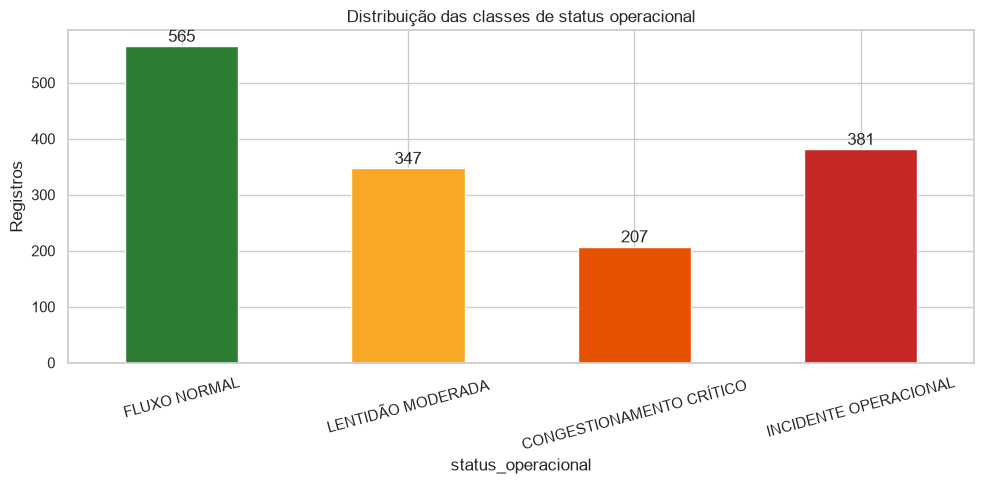

status_operacional
FLUXO NORMAL                37.7%
LENTIDÃO MODERADA           23.1%
CONGESTIONAMENTO CRÍTICO    13.8%
INCIDENTE OPERACIONAL       25.4%
Name: count, dtype: str


In [5]:
ordem = ["FLUXO NORMAL", "LENTIDÃO MODERADA", "CONGESTIONAMENTO CRÍTICO", "INCIDENTE OPERACIONAL"]
contagem = df["status_operacional"].value_counts().reindex(ordem)

ax = contagem.plot(kind="bar", color=["#2e7d32", "#f9a825", "#e65100", "#c62828"])
ax.set_title("Distribuição das classes de status operacional")
ax.set_ylabel("Registros")
plt.xticks(rotation=15)
for i, v in enumerate(contagem):
    ax.text(i, v + 8, str(v), ha="center")
plt.tight_layout()
plt.show()

print((contagem / len(df) * 100).round(1).astype(str) + "%")

**Interpretação:** a base é moderadamente desbalanceada — FLUXO NORMAL é a
classe majoritária (~38%) e CONGESTIONAMENTO CRÍTICO a minoritária (~14%). Esse
desbalanceamento é realista (a via opera normal na maior parte do tempo) e
justifica o uso de **split estratificado** e a análise de **F1-score por classe**,
já que a acurácia global pode mascarar erros nas classes minoritárias.

## 4. Distribuição das variáveis principais

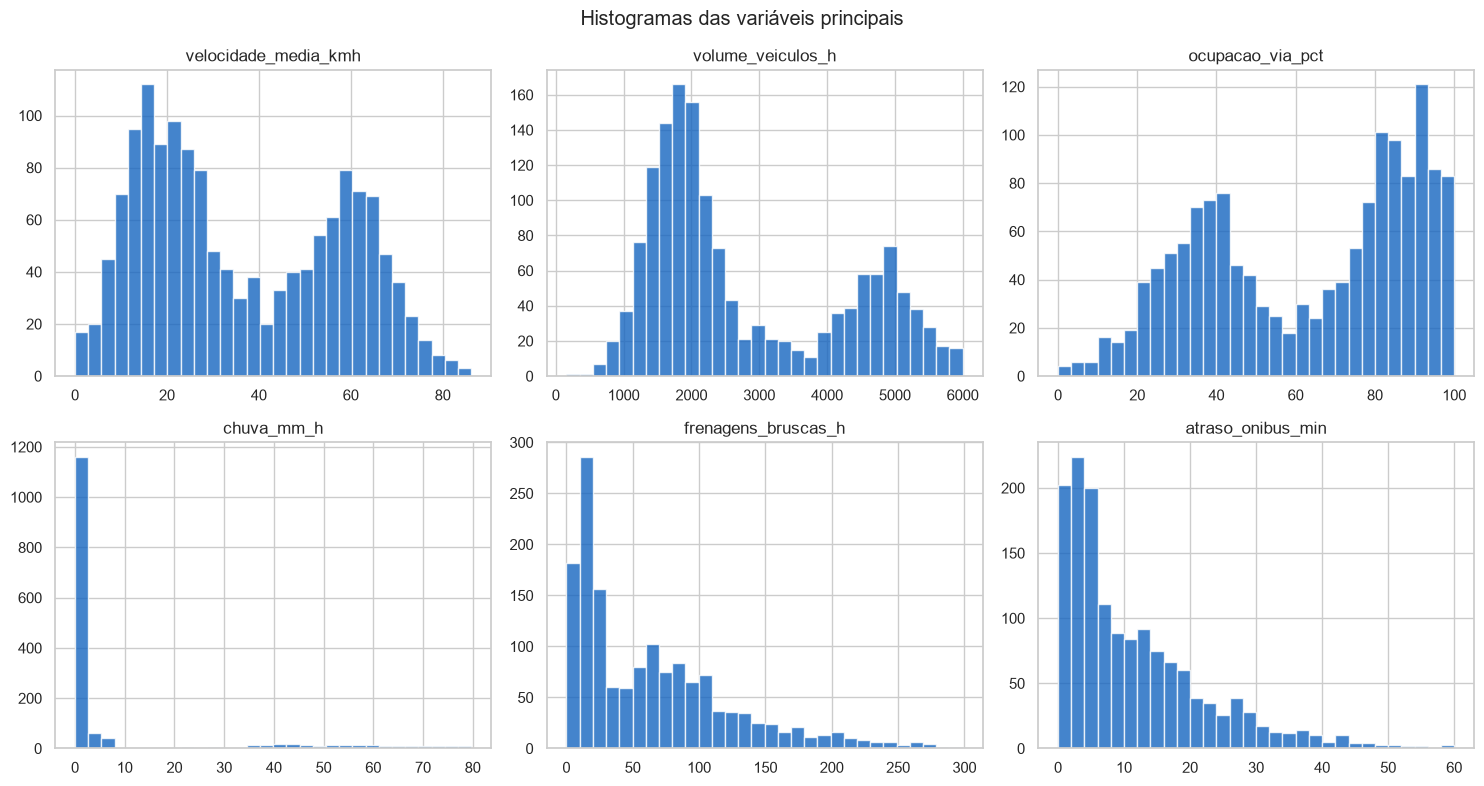

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
vars_plot = ["velocidade_media_kmh", "volume_veiculos_h", "ocupacao_via_pct",
             "chuva_mm_h", "frenagens_bruscas_h", "atraso_onibus_min"]
for ax, col in zip(axes.flat, vars_plot):
    df[col].hist(bins=30, ax=ax, color="#1565c0", alpha=0.8)
    ax.set_title(col)
plt.suptitle("Histogramas das variáveis principais")
plt.tight_layout()
plt.show()

**Interpretação:** a velocidade apresenta distribuição **bimodal** — um pico
em torno de 60 km/h (operação normal) e outro abaixo de 30 km/h (cenários
críticos). A chuva é zero na maioria dos registros, com uma cauda de eventos
intensos (35–80 mm/h). Frenagens bruscas e atraso de ônibus têm cauda longa à
direita, típica de eventos raros porém severos.

## 5. Velocidade × Status operacional

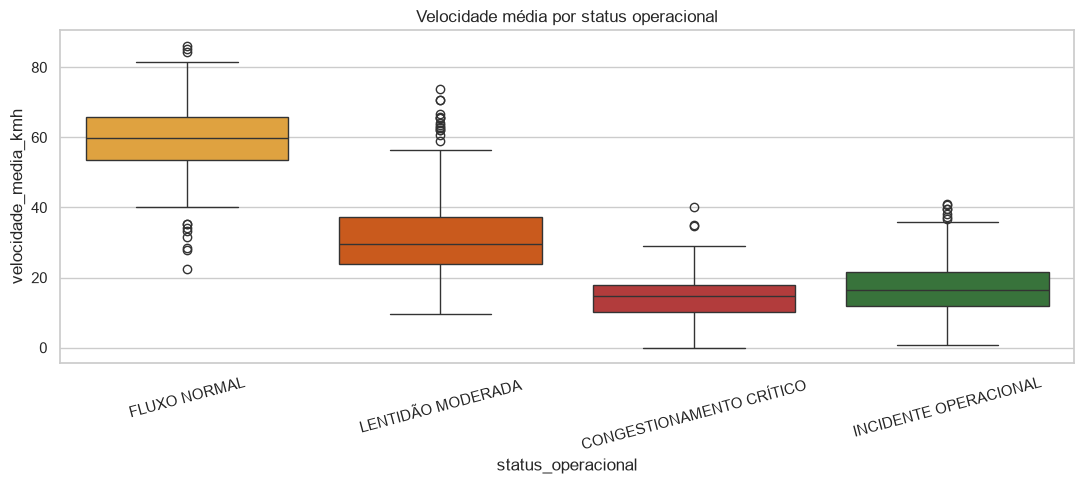

In [7]:
plt.figure(figsize=(11, 5))
sns.boxplot(data=df, x="status_operacional", y="velocidade_media_kmh",
            order=ordem, hue="status_operacional", legend=False,
            palette=["#2e7d32", "#f9a825", "#e65100", "#c62828"])
plt.title("Velocidade média por status operacional")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

**Interpretação:** a velocidade separa bem FLUXO NORMAL (mediana ~60 km/h)
dos demais estados, mas há **sobreposição** entre CONGESTIONAMENTO CRÍTICO e
INCIDENTE OPERACIONAL (ambos < 20 km/h). Isso indica que a velocidade sozinha
não distingue essas duas classes — o modelo precisará das variáveis de contexto
(acidentes, falha semafórica, frenagens) para separá-las. É exatamente aí que
esperamos os principais erros de classificação.

## 6. Volume de veículos × hora do dia

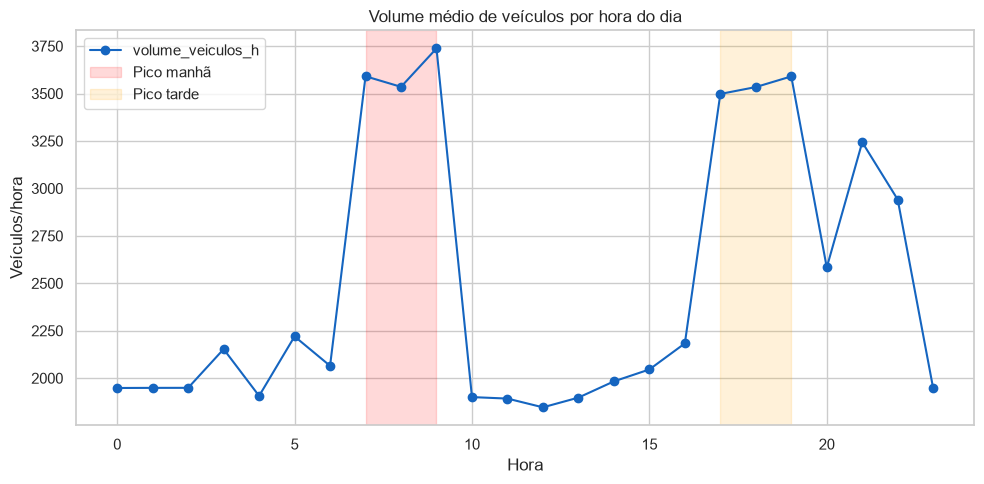

In [8]:
media_hora = df.groupby("hora")["volume_veiculos_h"].mean()
ax = media_hora.plot(marker="o", color="#1565c0")
ax.set_title("Volume médio de veículos por hora do dia")
ax.set_xlabel("Hora")
ax.set_ylabel("Veículos/hora")
ax.axvspan(7, 9, alpha=0.15, color="red", label="Pico manhã")
ax.axvspan(17, 19, alpha=0.15, color="orange", label="Pico tarde")
plt.legend()
plt.tight_layout()
plt.show()

**Interpretação:** os picos de volume coincidem com os horários de pico
(7–9h e 17–19h), refletindo a regra causal usada na geração da base e o
comportamento real de corredores urbanos.

## 7. Chuva × Velocidade

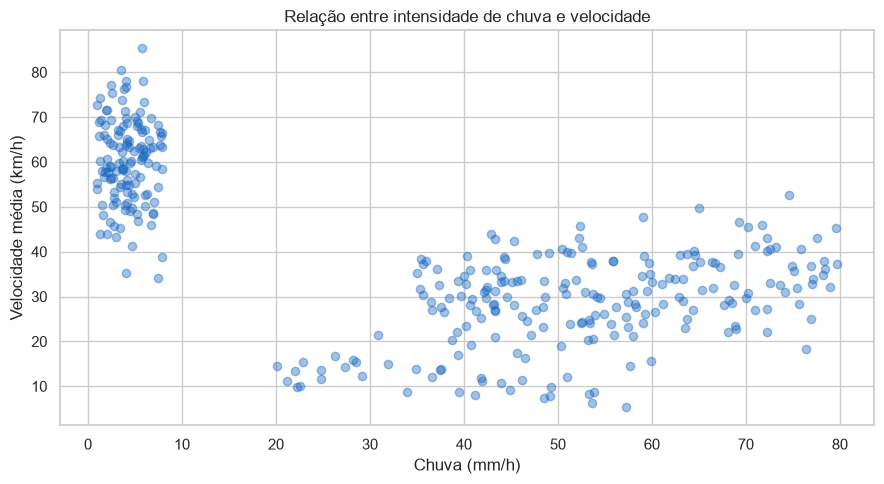

Correlação chuva × velocidade: -0.101


In [9]:
com_chuva = df[df["chuva_mm_h"] > 0]
plt.figure(figsize=(9, 5))
plt.scatter(com_chuva["chuva_mm_h"], com_chuva["velocidade_media_kmh"],
            alpha=0.4, c="#1565c0")
plt.xlabel("Chuva (mm/h)")
plt.ylabel("Velocidade média (km/h)")
plt.title("Relação entre intensidade de chuva e velocidade")
plt.tight_layout()
plt.show()

print("Correlação chuva × velocidade:",
      round(df["chuva_mm_h"].corr(df["velocidade_media_kmh"]), 3))

**Interpretação:** há correlação negativa entre chuva e velocidade —
chuvas acima de ~35 mm/h estão associadas a velocidades abaixo de 40 km/h,
validando a relação causal esperada em engenharia de tráfego.

## 8. Matriz de correlação

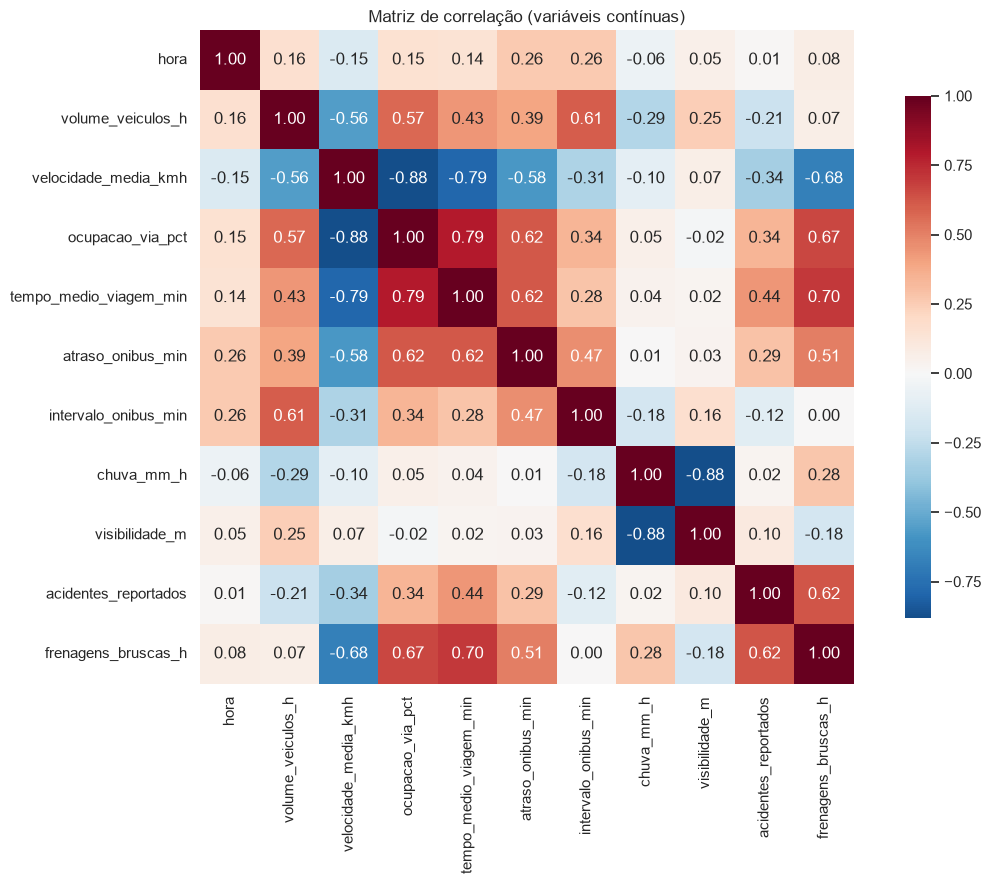

In [10]:
numericas = df.select_dtypes(include=np.number).drop(columns=["falha_semaforica",
    "obra_na_via", "evento_grande_porte"])
plt.figure(figsize=(12, 9))
sns.heatmap(numericas.corr(), annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, square=True, cbar_kws={"shrink": 0.8})
plt.title("Matriz de correlação (variáveis contínuas)")
plt.tight_layout()
plt.show()

**Interpretação:** as correlações mais fortes são coerentes com a física do
trânsito: **velocidade × ocupação** (negativa), **velocidade × tempo de viagem**
(negativa), **frenagens × acidentes** (positiva) e **chuva × visibilidade**
(negativa). Nenhum par apresenta correlação ≈ 1.0, o que afastaria suspeita de
variável duplicada/vazamento.

## 9. Pré-processamento

Etapas:
1. Remoção da coluna `cenario_origem` (auditoria da geração — usá-la no treino seria **vazamento de dados**)
2. Imputação de ausentes pela **mediana**
3. Encoding da variável categórica `dia_semana` (one-hot)
4. Padronização (`StandardScaler`) — necessária para KNN/SVM/MLP
5. Split estratificado: 70% treino / 15% validação / 15% teste

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. remove coluna de auditoria
df_prep = df.drop(columns=["cenario_origem"])

# 2. imputação pela mediana (apenas colunas numéricas com ausentes)
for col in df_prep.columns[df_prep.isna().any()]:
    mediana = df_prep[col].median()
    df_prep[col] = df_prep[col].fillna(mediana)
    print(f"{col}: ausentes imputados com mediana = {mediana}")

assert df_prep.isna().sum().sum() == 0, "Ainda há ausentes!"
print("\nBase sem valores ausentes.")

velocidade_media_kmh: ausentes imputados com mediana = 30.2
ocupacao_via_pct: ausentes imputados com mediana = 70.45
atraso_onibus_min: ausentes imputados com mediana = 7.9
chuva_mm_h: ausentes imputados com mediana = 0.0
visibilidade_m: ausentes imputados com mediana = 8377.0

Base sem valores ausentes.


In [12]:
# 3. one-hot encoding do dia da semana
df_prep = pd.get_dummies(df_prep, columns=["dia_semana"], dtype=int)

# salva a base tratada (entregável)
df_prep.to_csv("../dados/base_tratada.csv", index=False)
print(f"base_tratada.csv salva com {df_prep.shape[1]} colunas")
df_prep.head(3)

base_tratada.csv salva com 22 colunas


,hora,volume_veiculos_h,velocidade_media_kmh,ocupacao_via_pct,tempo_medio_viagem_min,atraso_onibus_min,intervalo_onibus_min,chuva_mm_h,visibilidade_m,acidentes_reportados,...,evento_grande_porte,frenagens_bruscas_h,status_operacional,dia_semana_domingo,dia_semana_quarta,dia_semana_quinta,dia_semana_sabado,dia_semana_segunda,dia_semana_sexta,dia_semana_terca
0,5,3925,27.3,97.0,58.6,24.4,6.4,0.0,8091.0,0,...,0,132.5,INCIDENTE OPERACIONAL,0,0,0,0,0,0,1
1,17,2130,15.2,88.2,85.1,19.8,9.1,0.0,6597.0,2,...,0,266.4,INCIDENTE OPERACIONAL,0,0,1,0,0,0,0
2,18,2171,50.4,25.2,14.8,1.8,5.5,0.0,10000.0,0,...,0,13.2,FLUXO NORMAL,1,0,0,0,0,0,0


In [13]:
# 4 e 5. separação X/y, split estratificado e padronização
X = df_prep.drop(columns=["status_operacional"])
y = df_prep["status_operacional"]

# 70% treino / 15% val / 15% teste
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.1765, stratify=y_temp, random_state=42)

print(f"Treino:    {len(X_train)} ({len(X_train)/len(X):.0%})")
print(f"Validação: {len(X_val)} ({len(X_val)/len(X):.0%})")
print(f"Teste:     {len(X_test)} ({len(X_test)/len(X):.0%})")

# scaler ajustado APENAS no treino (evita vazamento)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)
print("\nPadronização aplicada (fit apenas no treino).")

Treino:    1049 (70%)
Validação: 226 (15%)
Teste:     225 (15%)

Padronização aplicada (fit apenas no treino).


**Por que o scaler é ajustado só no treino?** Se o `fit` usasse toda a base,
estatísticas do conjunto de teste "vazariam" para o treino, inflando as métricas.
Esse cuidado será repetido no script `treinar.py`.

## Conclusões da EDA

- A base cobre os 5 cenários críticos exigidos, com relações causais coerentes.
- Velocidade e ocupação são as variáveis mais discriminantes, mas **não separam**
  CONGESTIONAMENTO de INCIDENTE — as variáveis de contexto serão decisivas.
- O desbalanceamento moderado exige avaliação por F1-score por classe, não só acurácia.
- Ausentes (~2%) tratados por mediana; categóricas via one-hot; contínuas padronizadas.

**Próxima etapa:** treinamento e comparação dos modelos (`src/treinar.py`).